# Logger session overview: data reliability, head angle, cameras, spikes
`2026-09-09_15-15_rPG007_P1500_RobotInteract_45min`: wireless Intan512 logger, 6 Basler cameras, IMU-based head orientation, JRClust spikes.

Modalities are read through the analysisVR loaders (`session_modality_from_nas`). Spikes are extracted in memory with
`ephys_preprocessing.postproc_logger_ephys.extract_jrc_spikes_logger`, the same function the `Spikes-SpikeClusterMetadata` analytic now uses for logger sessions.

**Timebase.** Every table carries `<m>_ephys_timestamp` in µs on the ephys clock (`sample_id * 50`; cameras keep the exact IR-burst onset).
Ephys time contains 47 spurious 192 ms zero pads, so it runs ahead of real time after 263 s; all modalities share it, so they align with each other.
See the session `README.md` and the `problem_intervals` / `timebase_segments` keys.

**Sections.** 1 modality health · 2 head angle (is it the integrated gyro? which yaw to use?) · 3 cameras · 4 spikes and which of them to trust ·
5 joined 40 ms table · 6 summary of what is reliable.

In [1]:
import os, sys
REPO = os.path.abspath('..')                      # this notebook lives in analysisVR/scripted_plotting
sys.path.insert(0, REPO); sys.path.insert(0, os.path.dirname(REPO))   # analysisVR, and VirtualReality (baseVR)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import h5py
import cv2

import analytics_processing.sessions_from_nas_parsing as sp
from analytics_processing.modality_loading import session_modality_from_nas as load
from ephys_preprocessing.postproc_logger_ephys import extract_jrc_spikes_logger

pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 9})

SESSION = '2026-09-09_15-15_rPG007_P1500_RobotInteract_45min'
try:
    F = sp.sessionnames2fullfnames([SESSION])[0][0]
except (ValueError, IndexError):
    # baseVR.device_paths() does not know every user/OS combination, fall back to the NAS path
    F = ('/Volumes/large/BMI/VirtualReality/SpatialSequenceLearning/RUN_rPG007/rPG007_P1500/'
         f'{SESSION}/{SESSION}.hdf5')
D = os.path.dirname(F)
print(F)
with pd.HDFStore(F, 'r') as store:
    print(store.keys())

Could not import mea1k_modules.mea1k_post_processing. Make sure ephysVR repository is available.


/Volumes/large/BMI/VirtualReality/SpatialSequenceLearning/RUN_rPG007/rPG007_P1500/2026-09-09_15-15_rPG007_P1500_RobotInteract_45min/2026-09-09_15-15_rPG007_P1500_RobotInteract_45min.hdf5


['/barometer', '/cam1_packages', '/cam2_packages', '/cam3_packages', '/cam4_packages', '/cam5_packages', '/cam6_packages', '/gap_classification', '/imu', '/ir_sync', '/luxmeter', '/magnetometer', '/metadata', '/orientation', '/power', '/problem_intervals', '/timebase_segments']


## 1. Modalities and their health

In [2]:
meta = load(F, 'metadata')
print({k: meta[k] for k in ('session_name', 'paradigm_id', 'animal_id', 'start_time', 'duration_minutes') if k in meta})

ori = load(F, 'orientation')
cams = {k: load(F, f'cam{k}_packages') for k in range(1, 7)}
problems = load(F, 'problem_intervals')
segments = load(F, 'timebase_segments')
mag = load(F, 'magnetometer')
imu = load(F, 'imu', columns=['imu_sample_id', 'imu_ephys_timestamp', 'imu_acc_clipped',
                              *[f'imu_{s}_{c}' for s in ('gyro', 'acc') for c in 'xyz']])
traces, mapping = load(F, 'ephys_traces')       # memmap (512 ch, samples) + mapping (row = channel)
N_SAMPLES = traces.shape[1]
T_END = N_SAMPLES / 20_000
t_imu = imu.imu_ephys_timestamp.values / 1e6
G = imu[[f'imu_gyro_{c}' for c in 'xyz']].values.astype(np.float64)    # rad/s
A = imu[[f'imu_acc_{c}' for c in 'xyz']].values.astype(np.float64)     # g

pads = problems[problems.category.str.startswith('zero_pad')]
malfunction = problems[problems.category == 'logger_malfunction_window']
MAL = (malfunction.start_sample.iloc[0] / 20_000, (malfunction.end_sample.iloc[0] + 1) / 20_000)
print(f'{len(pads)} zero pads ({(pads.category == "zero_pad_real_data_loss").sum()} real data loss), '
      f'malfunction window {MAL[0]:.1f}-{MAL[1]:.1f} s')

{'session_name': '2026-09-09_15-15_rPG007_P1500_RobotInteract_45min', 'paradigm_id': 1500, 'animal_id': 7, 'start_time': '2026-09-09_15-15', 'duration_minutes': 45}


53 zero pads (6 real data loss), malfunction window 2268.7-2292.8 s


In [3]:
# Health of each stream: rows, rate, and every gap longer than 2.5 sample periods. A gap that contains a zero pad is
# the known logger dropout (all sensors stop together); a gap without one would be an unexplained loss.
def gap_stats(sample_ids, nominal_hz):
    dt = np.diff(sample_ids) / 20_000
    g = np.flatnonzero(dt > 2.5 / nominal_hz)
    spans_pad = [((pads.start_sample.values >= sample_ids[i]) & (pads.start_sample.values <= sample_ids[i + 1])).any() for i in g]
    return len(g), int(np.sum(spans_pad)), dt.max() if len(dt) else np.nan

lux = load(F, 'luxmeter'); power = load(F, 'power'); baro = load(F, 'barometer')
health = []
for key, df, col, hz, values in [
        ('imu', imu, 'imu', 6666.67, [f'imu_{s}_{c}' for s in ('gyro', 'acc') for c in 'xyz']),
        ('magnetometer', mag, 'magnetometer', 98.5, [f'magnetometer_{c}' for c in 'xyz']),
        ('barometer', baro, 'barometer', 98.5, ['barometer_altitude', 'barometer_temperature']),
        ('luxmeter', lux, 'luxmeter', 100, ['luxmeter_lux']),
        ('power', power, 'power', 1000, ['power_V_bat', 'power_I_bat_mA']),
        ('orientation', ori, 'orientation', 100, ['orientation_yaw', 'orientation_pitch', 'orientation_roll'])]:
    n_gap, n_pad, max_gap = gap_stats(df[f'{col}_sample_id'].values, hz)
    health.append({'key': key, 'rows': len(df), 'rate_Hz': round(20_000 / np.median(np.diff(df[f'{col}_sample_id'])), 1),
                   'gaps': n_gap, 'gaps_at_zero_pad': n_pad, 'max_gap_s': round(max_gap, 3),
                   'NaN': int(df[values].isna().sum().sum()),
                   'interpolated': int(df[f'{col}_ephys_patched'].sum()) if f'{col}_ephys_patched' in df else 0})
c1 = cams[1]
health.append({'key': 'cam1..6_packages', 'rows': len(c1), 'rate_Hz': round(1e6 / np.median(np.diff(c1.cam1_image_ephys_timestamp)), 2),
               'gaps': int((np.diff(c1.cam1_image_ephys_timestamp) > 2.5e6 / 30).sum()), 'gaps_at_zero_pad': np.nan, 'max_gap_s': np.nan,
               'NaN': int(c1.cam1_image_ephys_timestamp.isna().sum()), 'interpolated': int(c1.cam1_image_ephys_patched.sum())})
health = pd.DataFrame(health).set_index('key')
print('accelerometer samples at +-16 g:', int(imu.imu_acc_clipped.sum()),
      '| max |gyro|:', round(np.abs(G).max(), 2), 'rad/s (no saturation)')
health

accelerometer samples at +-16 g: 19 | max |gyro|: 17.01 rad/s (no saturation)


,rows,rate_Hz,gaps,gaps_at_zero_pad,max_gap_s,NaN,interpolated
key,,,,,,,
imu,17318456,6666.7,53,53.0,0.192,0,0
magnetometer,270602,98.5,48,48.0,0.404,0,0
barometer,270602,98.5,48,48.0,0.404,0,0
luxmeter,270602,100.0,47,47.0,0.405,0,0
power,2742448,1000.0,53,53.0,0.193,0,0
orientation,275263,100.0,0,0.0,0.010,0,1020
cam1..6_packages,81000,30.0,26,NaN,NaN,0,61


Every sensor gap coincides with a zero pad (the orientation table has no gaps because it was interpolated across them, `ephys_patched`),
there are no NaNs, and the accelerometer clipped on 19 samples only. The camera row shows no frame interval > 2.5 frames: frames are
never dropped; frames whose IR code could not be read got an interpolated time (`image_ephys_patched`).

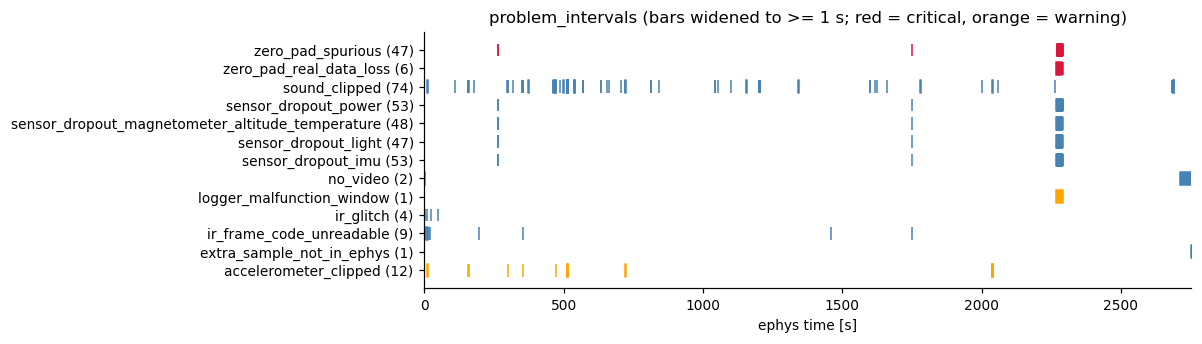

In [4]:
def shade_problems(ax, t_unit=1e6, label=True):
    """Shade zero pads (red: real data loss, grey: spurious) and the malfunction window on a time axis in s."""
    for _, r in malfunction.iterrows():
        ax.axvspan(r.start_sample * 50 / t_unit, r.end_sample * 50 / t_unit, color='orange', alpha=.15, lw=0,
                   label='malfunction window' if label else None)
    for _, r in pads.iterrows():
        real = r.category == 'zero_pad_real_data_loss'
        ax.axvline(r.start_sample * 50 / t_unit, color='crimson' if real else 'grey', lw=.6, alpha=.8 if real else .4)

cats = problems.groupby('category')
fig, ax = plt.subplots(figsize=(11, 3.2))
for i, (cat, d) in enumerate(cats):
    s, e = d.start_sample.values / 20_000, (d.end_sample.values + 1) / 20_000
    ax.broken_barh(list(zip(s, np.maximum(e - s, 1.0))), (i - .35, .7), color='crimson' if 'critical' in d.severity.values else
                   'orange' if 'warning' in d.severity.values else 'steelblue')   # min width 1 s so short ones are visible
ax.set_yticks(range(len(cats))); ax.set_yticklabels([f'{c} ({len(d)})' for c, d in cats])
ax.set_xlabel('ephys time [s]'); ax.set_title('problem_intervals (bars widened to >= 1 s; red = critical, orange = warning)')
ax.set_xlim(0, T_END); plt.tight_layout()

## 2. Head angle
The `orientation` table holds two sensor fusions, both computed at 100 Hz by the extractor (`_original/orientation_rpy.mat`):
- `orientation_q_*` / `orientation_yaw|pitch|roll`: 9-axis (gyro + accelerometer + magnetometer, hard-iron offset `b`, expected field `expmfs`)
- `orientation_q_imu_*` / `orientation_*_imu`: 6-axis (gyro + accelerometer, no magnetometer)

Yaw/pitch/roll are the ZYX Euler angles of the quaternion, which rotates head (sensor) axes into the world frame. Below:
(a) is the orientation the integrated gyroscope, (b) are pitch/roll anchored to gravity, (c) is the yaw anchored to magnetic north.

In [5]:
# quaternion helpers, (w, x, y, z) in the last axis; world = R(q) @ head
def qmul(a, b):
    w1, x1, y1, z1 = np.moveaxis(a, -1, 0); w2, x2, y2, z2 = np.moveaxis(b, -1, 0)
    return np.stack([w1 * w2 - x1 * x2 - y1 * y2 - z1 * z2, w1 * x2 + x1 * w2 + y1 * z2 - z1 * y2,
                     w1 * y2 - x1 * z2 + y1 * w2 + z1 * x2, w1 * z2 + x1 * y2 - y1 * x2 + z1 * w2], -1)
def qconj(q): return q * np.array([1., -1, -1, -1])
def rotate(q, v): return qmul(qmul(q, np.concatenate([np.zeros(v.shape[:-1] + (1,)), v], -1)), qconj(q))[..., 1:]
def euler_zyx(q):
    w, x, y, z = np.moveaxis(q, -1, 0)
    return np.rad2deg(np.stack([np.arctan2(2 * (w * z + x * y), 1 - 2 * (y * y + z * z)),
                                np.arcsin(np.clip(2 * (w * y - z * x), -1, 1)),
                                np.arctan2(2 * (w * x + y * z), 1 - 2 * (x * x + y * y))], -1))
def wrap(d): return (d + 180) % 360 - 180

Q = {'9-axis': ori[[f'orientation_q_{c}' for c in 'wxyz']].values,
     '6-axis': ori[[f'orientation_q_imu_{c}' for c in 'wxyz']].values}
for name, sfx in [('9-axis', ''), ('6-axis', '_imu')]:
    err = wrap(euler_zyx(Q[name]) - ori[[f'orientation_{c}{sfx}' for c in ('yaw', 'pitch', 'roll')]].values)
    assert np.abs(err).max() < 1e-6, name        # the stored Euler angles are exactly the quaternion's ZYX angles

t_ori = ori.orientation_ephys_timestamp.values / 1e6
def in_intervals(sample_ids, iv):
    a, b = np.sort(iv.start_sample.values), iv.end_sample.values[np.argsort(iv.start_sample.values)]
    k = np.searchsorted(a, sample_ids, side='right') - 1
    return (k >= 0) & (sample_ids <= b[np.clip(k, 0, None)])
near_pad = pads.assign(start_sample=pads.start_sample - 2_000, end_sample=pads.end_sample + 2_000)   # +-100 ms
clean_ori = ~in_intervals(ori.orientation_sample_id.values, near_pad) & ~in_intervals(ori.orientation_sample_id.values, malfunction)
print(f'{clean_ori.mean():.1%} of orientation samples are > 100 ms from a pad and outside the malfunction window')

99.1% of orientation samples are > 100 ms from a pad and outside the malfunction window


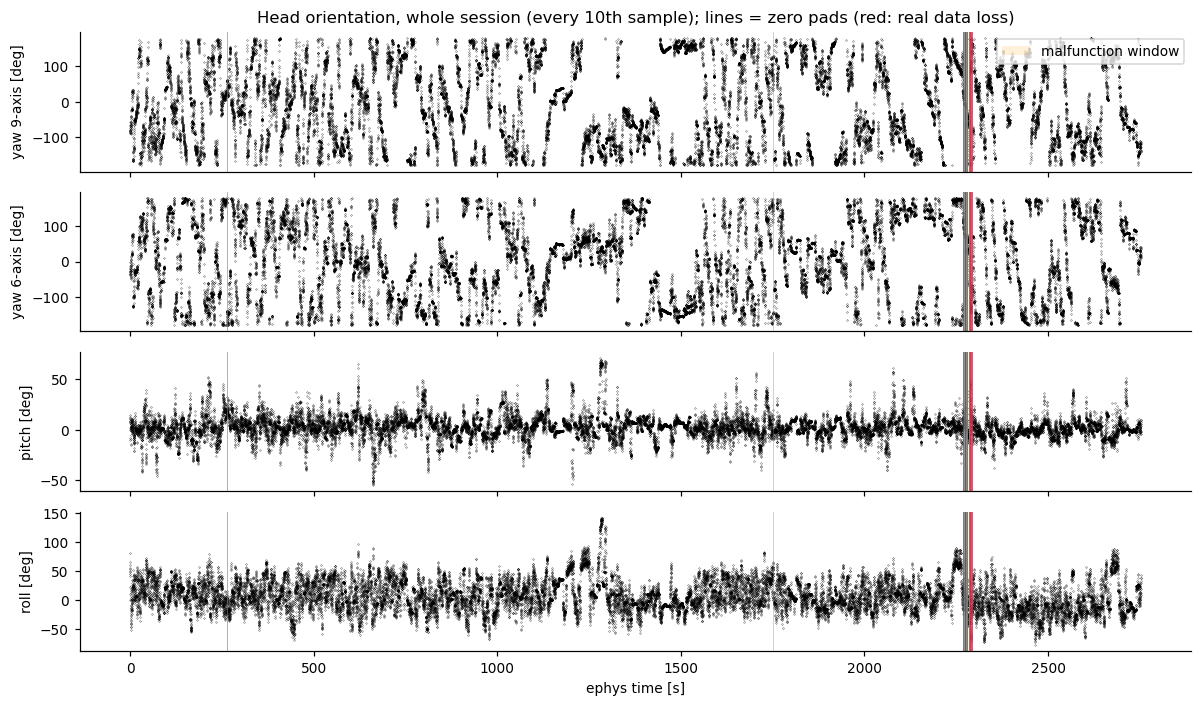

In [6]:
fig, axes = plt.subplots(4, 1, figsize=(11, 6.5), sharex=True)
for ax, (c, lab) in zip(axes, [('yaw', 'yaw 9-axis'), ('yaw_imu', 'yaw 6-axis'), ('pitch_imu', 'pitch'), ('roll_imu', 'roll')]):
    ax.plot(t_ori[::10], ori[f'orientation_{c}'].values[::10], '.', ms=.4, color='k')   # dots: yaw wraps at +-180
    shade_problems(ax, label=c == 'yaw'); ax.set_ylabel(f'{lab} [deg]')
axes[0].legend(loc='upper right'); axes[-1].set_xlabel('ephys time [s]')
axes[0].set_title('Head orientation, whole session (every 10th sample); lines = zero pads (red: real data loss)')
plt.tight_layout()

### 2a. Is the orientation the integrated gyroscope?
If the fused quaternion is the integral of the gyro, its body-frame angular velocity, `2 conj(q) dq/dt`, must equal the gyro on all
three axes. (`d(yaw)/dt` alone is not a good test: it equals gyro z only when the head is level.)

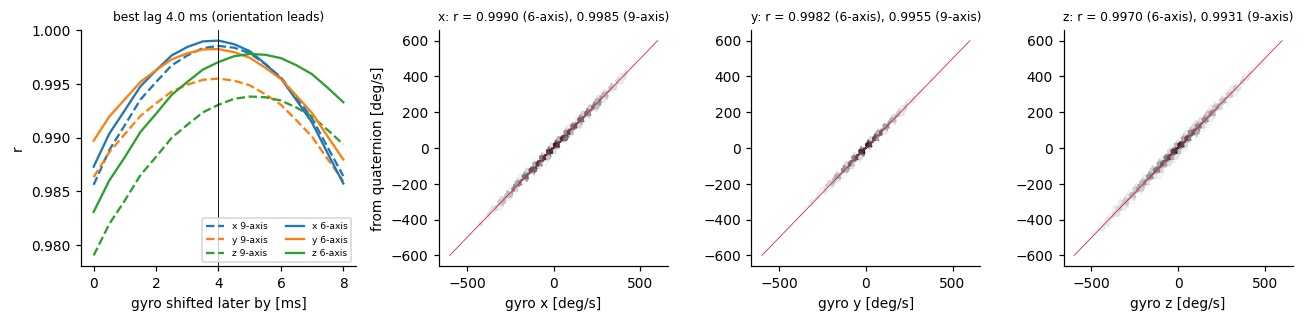

In [7]:
csG = np.vstack([np.zeros(3), np.cumsum(G, 0)])
def gyro_mean(t, half=.005):
    """Mean gyro [deg/s] in [t - half, t + half]."""
    a, b = np.searchsorted(t_imu, t - half), np.searchsorted(t_imu, t + half)
    return np.rad2deg((csG[b] - csG[a]) / np.maximum(b - a, 1)[:, None])

def body_rate(q):
    flip = np.where((q[1:] * q[:-1]).sum(1) < 0, -1., 1.)          # remove q / -q sign flips before differentiating
    q = q * np.cumprod(np.r_[1., flip])[:, None]
    return np.rad2deg(2 * qmul(qconj(q), np.gradient(q, t_ori, axis=0))[:, 1:])
W_BODY = {name: body_rate(q) for name, q in Q.items()}

lags_ms = np.arange(0, 8.01, .5)
r_lag = {name: np.array([[np.corrcoef(W_BODY[name][clean_ori, i], gyro_mean(t_ori[clean_ori] + l / 1e3)[:, i])[0, 1]
                          for i in range(3)] for l in lags_ms]) for name in Q}
LAG = lags_ms[np.argmax(r_lag['6-axis'].mean(1))] / 1e3
g_lag = gyro_mean(t_ori + LAG)

fig, axes = plt.subplots(1, 4, figsize=(12, 3), gridspec_kw={'width_ratios': [1.2, 1, 1, 1]})
for name, ls in [('9-axis', '--'), ('6-axis', '-')]:
    for i, c in enumerate('xyz'):
        axes[0].plot(lags_ms, r_lag[name][:, i], ls, color=f'C{i}', label=f'{c} {name}')
axes[0].axvline(LAG * 1e3, color='k', lw=.6); axes[0].set_xlabel('gyro shifted later by [ms]'); axes[0].set_ylabel('r')
axes[0].legend(fontsize=6, ncol=2); axes[0].set_title(f'best lag {LAG * 1e3:.1f} ms (orientation leads)', fontsize=8)
sub = np.flatnonzero(clean_ori)[::5]
for i, (ax, c) in enumerate(zip(axes[1:], 'xyz')):
    ax.hexbin(g_lag[sub, i], W_BODY['6-axis'][sub, i], gridsize=60, bins='log', cmap='Greys', extent=(-600, 600, -600, 600))
    ax.plot([-600, 600], [-600, 600], color='crimson', lw=.5)
    ax.set_title(f'{c}: r = {r_lag["6-axis"][np.argmax(r_lag["6-axis"].mean(1)), i]:.4f} (6-axis), '
                 f'{r_lag["9-axis"][np.argmax(r_lag["6-axis"].mean(1)), i]:.4f} (9-axis)', fontsize=8)
    ax.set_xlabel(f'gyro {c} [deg/s]'); ax.set_ylabel('from quaternion [deg/s]' if i == 0 else '')
plt.tight_layout()

Second test: integrate the raw gyro ourselves (6.67 kHz, body frame) from the fused orientation at a random start, and compare with
the fused orientation 1, 5 and 30 s later. A fusion that is the integrated gyro plus small gravity/magnetic corrections should stay close.

In [8]:
rng = np.random.default_rng(0)
bad = np.r_[0, np.cumsum(~clean_ori)]
cand = np.flatnonzero(clean_ori & (t_ori > 5) & (t_ori < t_ori[-1] - 31))
cand = cand[bad[cand + 3001] - bad[cand] == 0]                 # the whole 30 s is clean
starts = np.sort(rng.choice(cand, 100, replace=False))
CHECK = [1, 5, 30]
end_ori = {T: starts + T * 100 for T in CHECK}                 # orientation is exactly 100 Hz, no gaps
i0 = np.searchsorted(t_imu, t_ori[starts] + LAG)
i_end = {T: np.searchsorted(t_imu, t_ori[end_ori[T]] + LAG) for T in CHECK}

# gyro-only rotation since the start (body frame): q_start * dq reproduces the start orientation propagated by the gyro
dq = np.tile([1., 0, 0, 0], (len(starts), 1)); dq_at = {T: np.empty_like(dq) for T in CHECK}
for k in range(1, (i_end[30] - i0).max() + 1):
    j = i0 + k
    w = 0.5 * (G[j] + G[j - 1]) * (t_imu[j] - t_imu[j - 1])[:, None]
    a = np.linalg.norm(w, axis=1, keepdims=True)
    dq = qmul(dq, np.hstack([np.cos(a / 2), np.sin(a / 2) * w / np.where(a > 0, a, 1)]))
    dq /= np.linalg.norm(dq, axis=1, keepdims=True)
    for T in CHECK:
        hit = i_end[T] - i0 == k
        dq_at[T][hit] = dq[hit]

rows = []
for name, q in Q.items():
    for T in CHECK:
        q_gyro, q_fused = qmul(q[starts], dq_at[T]), q[end_ori[T]]
        d = np.abs(wrap(euler_zyx(q_gyro) - euler_zyx(q_fused)))
        total = np.rad2deg(2 * np.arccos(np.clip(np.abs((q_gyro * q_fused).sum(1)), 0, 1)))
        rows.append({'fusion': name, 'after_s': T, 'yaw_med': np.median(d[:, 0]), 'pitch_med': np.median(d[:, 1]),
                     'roll_med': np.median(d[:, 2]), 'total_med': np.median(total), 'total_p90': np.percentile(total, 90)})
print('|gyro-only integration - fused orientation| [deg], 100 random clean windows')
pd.DataFrame(rows).set_index(['fusion', 'after_s']).round(1)

|gyro-only integration - fused orientation| [deg], 100 random clean windows


yaw_med  pitch_med  roll_med  total_med  total_p90
fusion after_s                                                    
9-axis 1            3.6        1.5       1.7        5.4        9.9
       5           14.7        4.6       5.4       18.3       39.0
       30          51.8        8.9      10.0       55.3      138.5
6-axis 1            0.5        0.6       0.8        1.3        2.8
       5            2.3        2.7       2.5        5.3       10.2
       30          12.7        7.2       6.4       19.3       43.1

### 2b. Pitch and roll vs gravity
While the head is still (gyro < 15 deg/s and |acc| within 5 % of 1 g over 100 ms), the accelerometer measures gravity only; rotated into
the world frame it should point straight up.

In [9]:
csA = np.vstack([np.zeros(3), np.cumsum(A, 0)])
a_, b_ = np.searchsorted(t_imu, t_ori + LAG - .05), np.searchsorted(t_imu, t_ori + LAG + .05)
acc_100ms = (csA[b_] - csA[a_]) / np.maximum(b_ - a_, 1)[:, None]
still = clean_ori & (np.linalg.norm(gyro_mean(t_ori + LAG, .05), axis=1) < 15) & (np.abs(np.linalg.norm(acc_100ms, axis=1) - 1) < .05)
tilt_err = {}
for name, q in Q.items():
    aw = rotate(q[still], acc_100ms[still])
    tilt_err[name] = np.rad2deg(np.arccos(np.clip(aw[:, 2] / np.linalg.norm(aw, axis=1), -1, 1)))
    print(f'{name}: angle between world-frame gravity and vertical, median {np.median(tilt_err[name]):.1f} deg, '
          f'p95 {np.percentile(tilt_err[name], 95):.1f} deg  (n = {still.sum():,} still samples)')

9-axis: angle between world-frame gravity and vertical, median 7.0 deg, p95 20.0 deg  (n = 59,889 still samples)
6-axis: angle between world-frame gravity and vertical, median 1.2 deg, p95 4.2 deg  (n = 59,889 still samples)


### 2c. Yaw vs magnetic north
Rotate the (hard-iron corrected) magnetometer into each fusion's world frame. If yaw is anchored to north, the horizontal field direction
stays constant. The extractor's calibration (`A`, `b`, `expmfs`) is read from `_original/orientation_rpy.mat`.

In [10]:
with h5py.File(os.path.join(D, '_original', 'orientation_rpy.mat'), 'r') as f:
    MAG_A, MAG_B, MAG_EXP = f['A'][()], f['b'][()].ravel(), float(f['expmfs'][()].squeeze())
print('A =', MAG_A.tolist(), '| b [uT] =', MAG_B.round(2), '| expected field [uT] =', round(MAG_EXP, 1))
t_mag = mag.magnetometer_ephys_timestamp.values / 1e6
M = (mag[[f'magnetometer_{c}' for c in 'xyz']].values * 100 - MAG_B) @ MAG_A.T     # Gauss -> uT, calibrated
oi = np.clip(np.searchsorted(t_ori, t_mag), 0, len(t_ori) - 1)
mclean = clean_ori[oi]
FLIP_Y = np.diag([1., -1, 1])

def north(q, Mb):
    mw = rotate(q, Mb)
    return np.arctan2(mw[:, 1], mw[:, 0]), np.rad2deg(np.arctan2(mw[:, 2], np.hypot(mw[:, 0], mw[:, 1])))
win30 = (t_mag[mclean] // 30).astype(int)
rows = []
for mlab, P in [('as stored', np.eye(3)), ('y axis flipped', FLIP_Y)]:
    for name, q in Q.items():
        h, incl = north(q[oi[mclean]], M[mclean] @ P.T)
        mvl = pd.Series(np.exp(1j * h)).groupby(win30).mean().abs()
        rows.append({'magnetometer': mlab, 'fusion': name,
                     'north_circ_std_within_30s_deg': np.rad2deg(np.sqrt(-2 * np.log(mvl.median()))),
                     'inclination_median_deg': np.median(incl), 'inclination_std_deg': np.std(incl)})
print(f'|B| median {np.median(np.linalg.norm(M, axis=1)):.1f} uT')
pd.DataFrame(rows).set_index(['magnetometer', 'fusion']).round(1)

A = [[1.0, 0.0, 0.0], [0.0, 1.0, 0.0], [0.0, 0.0, 1.0]] | b [uT] = [-14.23  -9.06 -51.71] | expected field [uT] = 38.5


|B| median 37.6 uT


north_circ_std_within_30s_deg  inclination_median_deg  inclination_std_deg
magnetometer   fusion                                                                            
as stored      9-axis                           85.0                   -41.0                 30.9
               6-axis                           80.8                   -37.7                 30.7
y axis flipped 9-axis                           26.3                   -48.6                 10.6
               6-axis                           12.9                   -47.8                  7.4

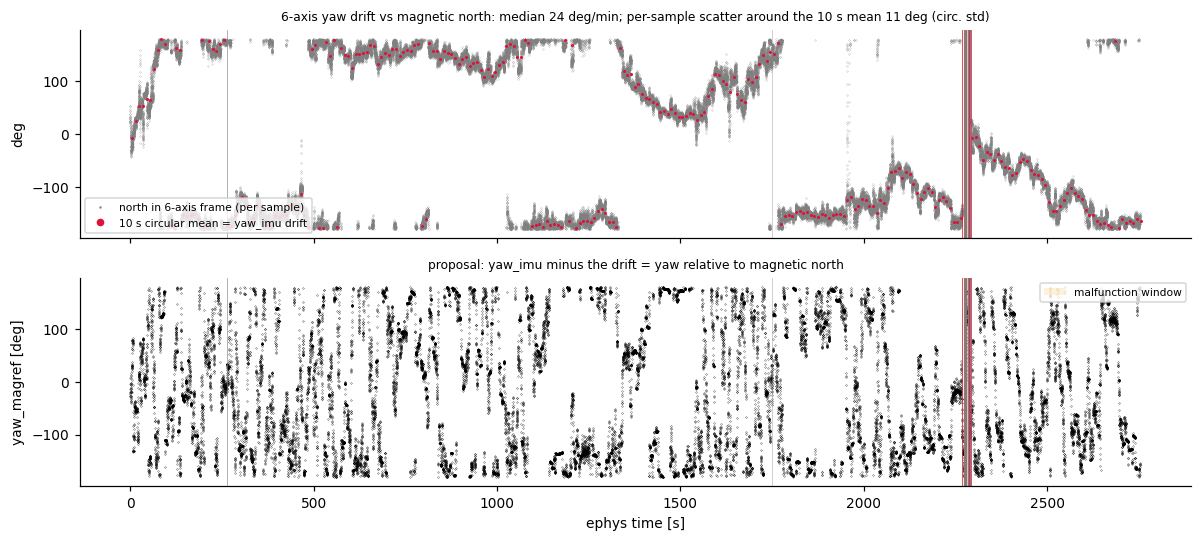

In [11]:
# north direction in the 6-axis world frame over the session = the 6-axis yaw drift (sign-inverted)
h6, _ = north(Q['6-axis'][oi], M @ FLIP_Y.T)
W10 = 10
grp = pd.Series(np.exp(1j * h6[mclean])).groupby((t_mag[mclean] // W10).astype(int)).mean()
grp = grp[grp.abs() > .8]                                  # skip 10 s windows with a disturbed field
t_off = (grp.index.values + .5) * W10
off_unwr = np.unwrap(np.angle(grp.values))
yaw_offset = np.rad2deg(np.interp(t_ori, t_off, off_unwr))
yaw_magref = wrap(ori.orientation_yaw_imu.values - yaw_offset)      # 0 = magnetic north; NOT a column of the hdf5

resid = wrap(np.rad2deg(h6) - np.interp(t_mag, t_off, np.rad2deg(off_unwr)))[mclean]
drift_rate = np.abs(np.diff(np.interp(np.arange(0, t_off[-1], 60), t_off, np.rad2deg(off_unwr))))   # deg per minute
fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
axes[0].plot(t_mag[mclean][::3], np.rad2deg(h6[mclean][::3]), '.', ms=.3, color='grey', label='north in 6-axis frame (per sample)')
axes[0].plot(t_off, wrap(np.rad2deg(off_unwr)), '.', ms=2, color='crimson', label=f'{W10} s circular mean = yaw_imu drift')
axes[0].set_ylabel('deg'); axes[0].legend(loc='lower left', fontsize=7, markerscale=4); shade_problems(axes[0], label=False)
axes[0].set_title(f'6-axis yaw drift vs magnetic north: median {np.median(drift_rate):.0f} deg/min; per-sample scatter around '
                  f'the 10 s mean {np.rad2deg(np.sqrt(-2 * np.log(np.abs(np.mean(np.exp(1j * np.deg2rad(resid))))))):.0f} deg (circ. std)', fontsize=8)
axes[1].plot(t_ori[::10], yaw_magref[::10], '.', ms=.4, color='k'); shade_problems(axes[1])
axes[1].set_ylabel('yaw_magref [deg]'); axes[1].set_xlabel('ephys time [s]'); axes[1].legend(loc='upper right', fontsize=7)
axes[1].set_title('proposal: yaw_imu minus the drift = yaw relative to magnetic north', fontsize=8)
plt.tight_layout()

**Head-angle verdict**
- **Yes, the orientation is the integrated gyroscope.** The quaternion's body-frame angular velocity matches gyro x/y/z with r ≥ 0.997
  (6-axis) when the gyro is shifted ~4 ms later: the orientation table leads the gyro by ~4 ms. Our own integration of the raw gyro stays
  within ~1° of the 6-axis fusion over 1 s and a few degrees over 5 s. Pitch and roll are anchored to gravity by the accelerometer.
- **Use the 6-axis angles (`orientation_*_imu`).** The 9-axis fusion was fed a magnetometer whose y axis is flipped relative to the IMU
  (flipping it makes north stable within 30 s; as stored it wanders by > 80°). As a result the 9-axis yaw departs from the gyro by
  tens of degrees within seconds, and its pitch/roll are also less accurate vs gravity. Do not use `orientation_yaw/pitch/roll`.
- **6-axis yaw is relative and drifts** against magnetic north (median ~25°/min measured per minute, fast in the first ~100 s, and a
  jump across the malfunction window). Fine for short-timescale head turns; for head direction use a north-referenced yaw. `yaw_magref` above is
  such a correction (yaw_imu minus the 10 s magnetometer-estimated drift); it is computed here only, not stored in the hdf5.

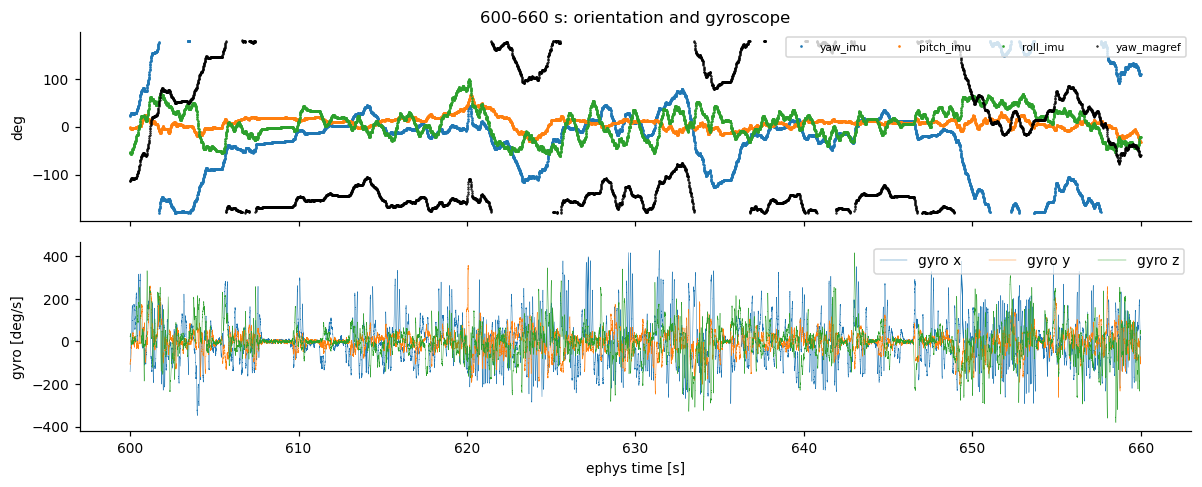

In [12]:
# zoom: 60 s, 6-axis orientation vs the raw gyroscope in the same window
t0, t1 = 600, 660
w = (t_ori >= t0) & (t_ori < t1); wi = (t_imu >= t0) & (t_imu < t1)
fig, axes = plt.subplots(2, 1, figsize=(11, 4.5), sharex=True)
for c in ['yaw_imu', 'pitch_imu', 'roll_imu']:
    axes[0].plot(t_ori[w], ori[f'orientation_{c}'].values[w], '.', ms=1.5, label=c)
axes[0].plot(t_ori[w], yaw_magref[w], '.', ms=1, color='k', label='yaw_magref')
axes[0].set_ylabel('deg'); axes[0].legend(ncol=4, loc='upper right', fontsize=7)
for i, c in enumerate('xyz'):
    axes[1].plot(t_imu[wi][::4], np.rad2deg(G[wi, i])[::4], lw=.3, label=f'gyro {c}')
axes[1].set_ylabel('gyro [deg/s]'); axes[1].legend(ncol=3, loc='upper right'); axes[1].set_xlabel('ephys time [s]')
axes[0].set_title(f'{t0}-{t1} s: orientation and gyroscope'); plt.tight_layout()

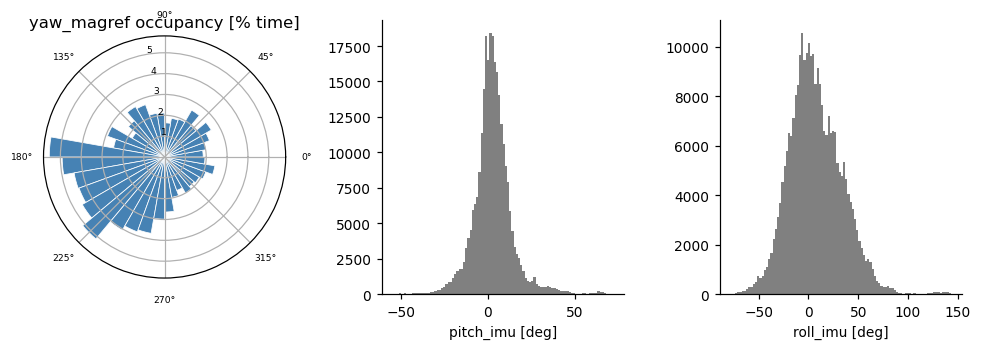

In [13]:
# head-direction occupancy (north-referenced yaw) and pitch/roll distributions, clean samples
fig = plt.figure(figsize=(9, 3.2))
ax = fig.add_subplot(131, projection='polar')
h, e = np.histogram(np.deg2rad(yaw_magref[clean_ori]), bins=36, range=(-np.pi, np.pi))
ax.bar(e[:-1], h / clean_ori.sum() * 100, width=np.diff(e), align='edge', color='steelblue', edgecolor='white', lw=.5)
ax.tick_params(labelsize=6); ax.set_rlabel_position(100); ax.set_title('yaw_magref occupancy [% time]')
for i, c in enumerate(['pitch_imu', 'roll_imu']):
    ax = fig.add_subplot(1, 3, i + 2)
    ax.hist(ori[f'orientation_{c}'].values[clean_ori], bins=100, color='grey'); ax.set_xlabel(f'{c} [deg]')
plt.tight_layout()

## 3. Cameras (`cam1_packages` ... `cam6_packages`)
All six cameras are triggered by the same Arduino pulse, so row *k* of every table is mp4 frame *k* and they share `image_ephys_timestamp`.

In [14]:
assert all(np.array_equal(cams[k][f'cam{k}_image_ephys_timestamp'].values, c1.cam1_image_ephys_timestamp.values) for k in cams)
pd.DataFrame({f'cam{k}': {'frames': len(c), 'sync ir_decoded': (c[f'cam{k}_image_sync_source'] == 'ir_decoded').sum(),
                          'sync interpolated (patched)': int(c[f'cam{k}_image_ephys_patched'].sum()),
                          'in real data loss': int(c[f'cam{k}_image_ephys_missing'].sum()),
                          'in malfunction window': int(c[f'cam{k}_image_in_malfunction_window'].sum())}
              for k, c in cams.items()})

,cam1,cam2,cam3,cam4,cam5,cam6
frames,81000,81000,81000,81000,81000,81000
sync ir_decoded,80936,80936,80936,80936,80936,80936
sync interpolated (patched),61,61,61,61,61,61
in real data loss,34,34,34,34,34,34
in malfunction window,471,471,471,471,471,471


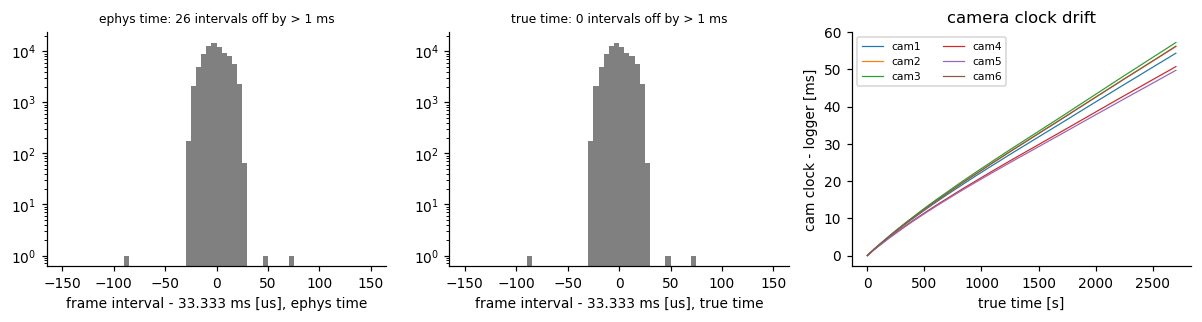

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
d_eph = np.diff(c1.cam1_image_ephys_timestamp.values) / 1e3
d_true = np.diff(c1.cam1_image_true_timestamp.values) / 1e3
for ax, d, nm in [(axes[0], d_eph, 'ephys time'), (axes[1], d_true, 'true time')]:
    ax.hist((d - 1e3 / 30) * 1e3, bins=np.arange(-150, 151, 5), color='grey'); ax.set_yscale('log')
    ax.set_xlabel(f'frame interval - 33.333 ms [us], {nm}')
    ax.set_title(f'{nm}: {(np.abs(d - 1e3 / 30) > 1).sum()} intervals off by > 1 ms', fontsize=8)
# camera hardware clocks vs logger true time (drift relative to the logger clock)
for k, c in cams.items():
    res = (c[f'cam{k}_image_cam_timestamp'] - (c[f'cam{k}_image_true_timestamp'] - c[f'cam{k}_image_true_timestamp'].iloc[0])) / 1e3
    axes[2].plot(c[f'cam{k}_image_true_timestamp'][::30] / 1e6, res[::30], lw=.8, label=f'cam{k}')
axes[2].set_xlabel('true time [s]'); axes[2].set_ylabel('cam clock - logger [ms]'); axes[2].legend(ncol=2, fontsize=7)
axes[2].set_title('camera clock drift'); plt.tight_layout()

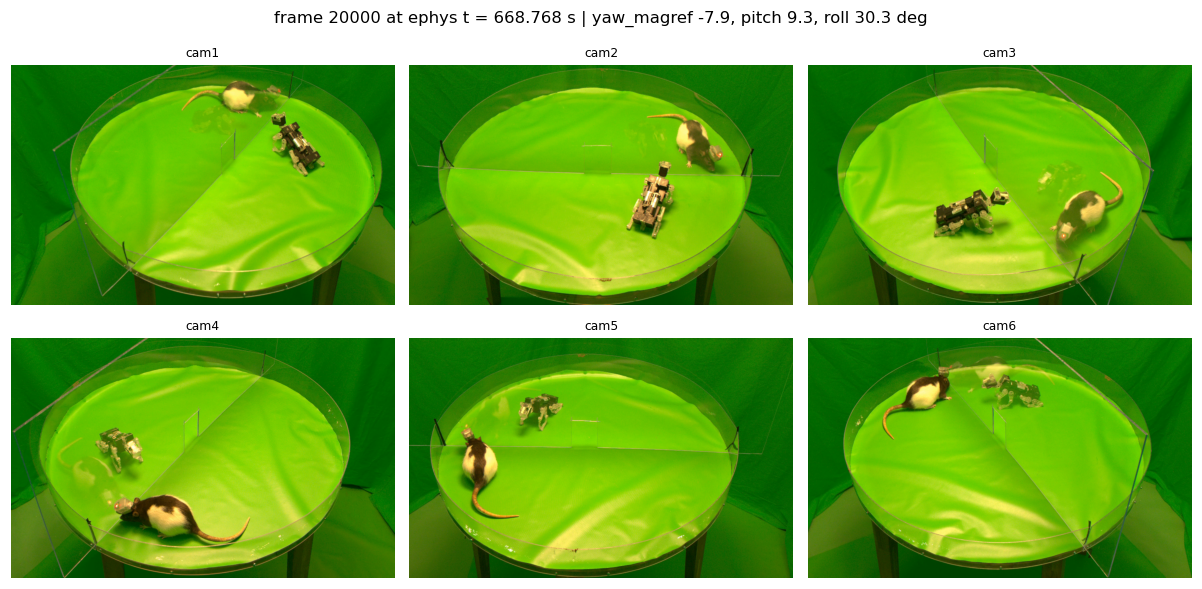

In [16]:
# one synchronized frame from every camera, with the head orientation at that moment
frame_id = 20_000
ts = c1.cam1_image_ephys_timestamp.values[frame_id]
oi_f = np.searchsorted(ori.orientation_ephys_timestamp.values, ts)
fig, axes = plt.subplots(2, 3, figsize=(11, 5.6))
for ax, k in zip(axes.ravel(), cams):
    cap = cv2.VideoCapture(os.path.join(D, f'cam{k}.mp4'))
    cap.set(cv2.CAP_PROP_POS_FRAMES, frame_id)
    ok, img = cap.read(); pos = cap.get(cv2.CAP_PROP_POS_FRAMES) - 1; cap.release()
    assert ok and pos == frame_id
    ax.imshow(img[..., ::-1]); ax.set_axis_off(); ax.set_title(f'cam{k}', fontsize=8)
fig.suptitle(f'frame {frame_id} at ephys t = {ts / 1e6:.3f} s | yaw_magref {yaw_magref[oi_f]:.1f}, '
             f'pitch {ori.orientation_pitch_imu.values[oi_f]:.1f}, roll {ori.orientation_roll_imu.values[oi_f]:.1f} deg')
plt.tight_layout()

**Camera verdict:** all 6 cameras have every frame, share one trigger time per frame, and the frame interval is 33.333 ms ± 30 µs in
true time. The 26 intervals off by > 1 ms in ephys time are the spurious zero pads (ephys time jumps by 192 ms there), not dropped frames.

## 4. Spikes (JRClust, curated)
`extract_jrc_spikes_logger` maps JRClust sites to `.dat` channels with the prm `siteMap`, uses `sample_id = spikeTimes - 1`,
drops clusters without a label or labelled `to_delete`, removes same-cluster spikes <= 1 ms apart (the duplicate spikes on a second site),
and flags spikes inside / within 5 ms of a zero pad and in the malfunction window. `gross_brain_area` is a placeholder (= shank name).

In [17]:
clusters, spikes = extract_jrc_spikes_logger(F)
print(len(spikes), 'spikes', clusters.cluster_type.value_counts().to_dict())
clusters.groupby(['shank_name', 'cluster_type']).size().unstack(fill_value=0)

4386219 spikes {'single': 186, 'noise': 39}


cluster_type,noise,single
shank_name,,
shank1,0,4
shank2,0,27
shank3,0,46
shank4,39,35
shank5,0,9
shank6,0,18
shank7,0,23
shank8,0,24


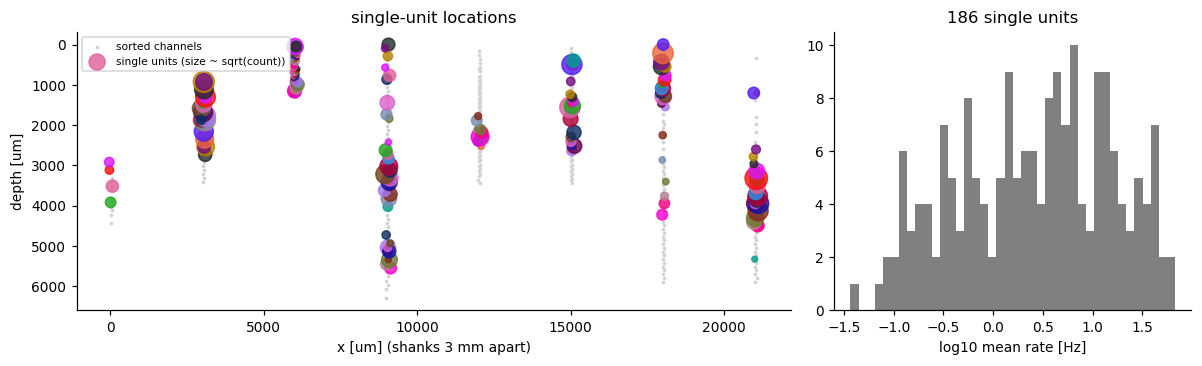

In [18]:
single = clusters[clusters.cluster_type == 'single']
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw={'width_ratios': [2, 1]})
ax = axes[0]
used = mapping[mapping.curated_trace]
ax.scatter(used.x, used.depth, s=2, color='lightgrey', label='sorted channels')
rng = np.random.default_rng(0)
ax.scatter(single.x + rng.uniform(-80, 80, len(single)), single.depth, s=np.sqrt(single.session_spike_count) / 2,
           c=single.cluster_color, alpha=.8, label='single units (size ~ sqrt(count))')
ax.set_xlabel('x [um] (shanks 3 mm apart)'); ax.set_ylabel('depth [um]'); ax.invert_yaxis(); ax.legend(fontsize=7)
ax.set_title('single-unit locations')
ax = axes[1]
rate = single.session_spike_count / T_END
ax.hist(np.log10(rate), bins=40, color='grey'); ax.set_xlabel('log10 mean rate [Hz]'); ax.set_title(f'{len(single)} single units')
plt.tight_layout()

### 4a. Which spikes to trust
Three kinds of suspect spikes:
1. **At zero pads.** The logger replaced 192 ms of data with zeros. Detections pile up at the step into and out of the pad, and the rate
   stays elevated for ~25-30 ms on both sides (filter ringing of the step), so the extractor's 5 ms flag is too narrow; use 30 ms.
2. **In the malfunction window** (2268.7-2292.8 s): 50 of the 53 pads are here, and timing is uncertain by up to ~0.2 s.
3. **The rate burst around the malfunction window**, checked in detail below.

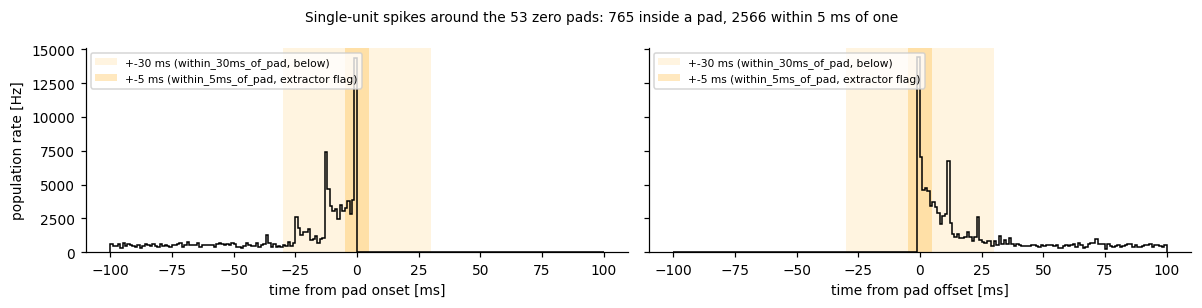

In [19]:
# spikes of all single units around pad onsets and offsets (1 ms bins), as population rate per pad
sg = spikes[spikes.cluster_id.isin(single.cluster_id)]
sid_sg = sg.sample_id.values
fig, axes = plt.subplots(1, 2, figsize=(11, 2.8), sharey=True)
for ax, edge, lab in [(axes[0], pads.start_sample.values, 'pad onset'), (axes[1], pads.end_sample.values + 1, 'pad offset')]:
    rel = np.concatenate([sid_sg[(sid_sg >= e - 2_000) & (sid_sg < e + 2_000)] - e for e in edge]) / 20
    ax.hist(rel, bins=np.arange(-100, 101, 1), weights=np.full(len(rel), 1000 / len(edge)), color='k', histtype='step')
    ax.axvspan(-30, 30, color='orange', alpha=.12, lw=0, label='+-30 ms (within_30ms_of_pad, below)')
    ax.axvspan(-5, 5, color='orange', alpha=.25, lw=0, label='+-5 ms (within_5ms_of_pad, extractor flag)')
    ax.set_xlabel(f'time from {lab} [ms]'); ax.legend(fontsize=7, loc='upper left')
axes[0].set_ylabel('population rate [Hz]')
fig.suptitle(f'Single-unit spikes around the {len(pads)} zero pads: {int(sg.in_zero_pad.sum())} inside a pad, '
             f'{int(sg.within_5ms_of_pad.sum())} within 5 ms of one', fontsize=9)
plt.tight_layout()

population rate median 1551 Hz, MAD 155 Hz; burst window 2256-2337 s (malfunction window 2268.7-2292.8 s inside it); other single seconds above threshold: [1099, 1432, 1526]


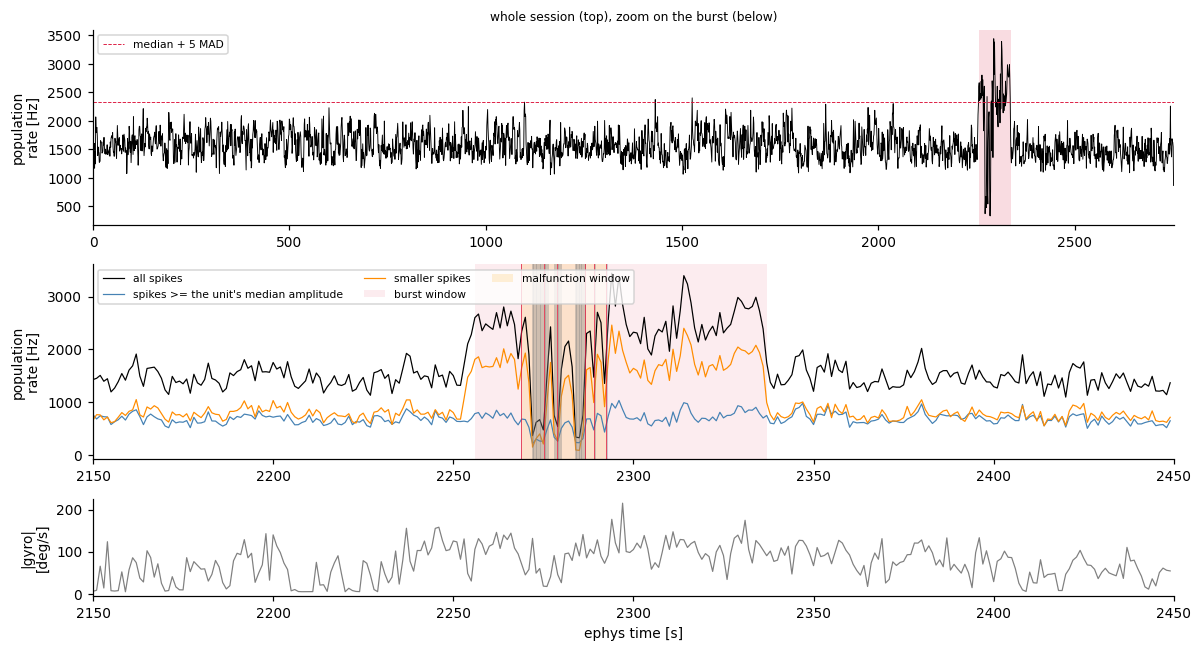

In [20]:
# population rate per second (single units); the burst = the run of > median + 5 MAD seconds around the malfunction window
t_sg = sid_sg / 20_000
n_sec = int(np.ceil(T_END))
pop = np.bincount(t_sg.astype(int), minlength=n_sec)[:n_sec]
med, mad = np.median(pop), np.median(np.abs(pop - np.median(pop)))
high = np.flatnonzero(pop > med + 5 * mad)
runs = np.split(high, np.flatnonzero(np.diff(high) > 3) + 1)
BURST = MAL                                  # grow from the malfunction window over high-rate runs <= 10 s away
while True:
    touching = [r for r in runs if r[0] <= BURST[1] + 10 and r[-1] + 1 >= BURST[0] - 10]
    grown = (min([BURST[0]] + [float(r[0]) for r in touching]), max([BURST[1]] + [float(r[-1] + 1) for r in touching]))
    if grown == BURST: break
    BURST = grown
other_high = [int(s) for s in high if not BURST[0] <= s < BURST[1]]
print(f'population rate median {med:.0f} Hz, MAD {mad:.0f} Hz; burst window {BURST[0]:.0f}-{BURST[1]:.0f} s '
      f'(malfunction window {MAL[0]:.1f}-{MAL[1]:.1f} s inside it); other single seconds above threshold: {other_high}')

# spike amplitude relative to the unit's own median amplitude in the session outside the burst
in_burst_t = (t_sg >= BURST[0]) & (t_sg < BURST[1])
amp = np.abs(sg.amplitude_uV.values)
unit_med_amp = pd.Series(amp[~in_burst_t]).groupby(sg.cluster_id.values[~in_burst_t]).median()
large = amp >= unit_med_amp.reindex(sg.cluster_id.values).values

t_a, t_b = 2150, 2450
sec = np.arange(t_a, t_b)
pop_large = np.bincount(t_sg[large].astype(int), minlength=n_sec)[:n_sec]
gyro_speed = np.linalg.norm(np.rad2deg(G), axis=1)
gs_sec = np.bincount(t_imu.astype(int), gyro_speed, minlength=n_sec)[:n_sec] / np.maximum(np.bincount(t_imu.astype(int), minlength=n_sec)[:n_sec], 1)
fig, (ax0, ax1, ax2) = plt.subplots(3, 1, figsize=(11, 6), gridspec_kw={'height_ratios': [2, 2, 1]})
ax2.sharex(ax1)
ax0.plot(np.arange(n_sec), pop, color='k', lw=.6); ax0.axhline(med + 5 * mad, color='crimson', lw=.6, ls='--', label='median + 5 MAD')
ax0.set_ylabel('population\nrate [Hz]'); ax0.legend(fontsize=7, loc='upper left'); ax0.set_xlim(0, T_END)
ax0.axvspan(*BURST, color='crimson', alpha=.15, lw=0); ax0.set_title('whole session (top), zoom on the burst (below)', fontsize=8)
ax1.plot(sec, pop[sec], color='k', lw=.8, label='all spikes')
ax1.plot(sec, pop_large[sec], color='steelblue', lw=.8, label="spikes >= the unit's median amplitude")
ax1.plot(sec, pop[sec] - pop_large[sec], color='darkorange', lw=.8, label='smaller spikes')
ax1.axvspan(*BURST, color='crimson', alpha=.08, lw=0, label='burst window'); shade_problems(ax1, label=True)
ax1.set_ylabel('population\nrate [Hz]'); ax1.legend(fontsize=7, ncol=3, loc='upper left')
ax2.plot(sec, gs_sec[sec], color='grey', lw=.8); ax2.set_ylabel('|gyro|\n[deg/s]'); ax2.set_xlabel('ephys time [s]')
ax1.set_xlim(t_a, t_b); plt.tight_layout()

spikes >= unit median amplitude: 778 Hz before vs 760 Hz in the burst; all spikes 1553 Hz vs 2556 Hz


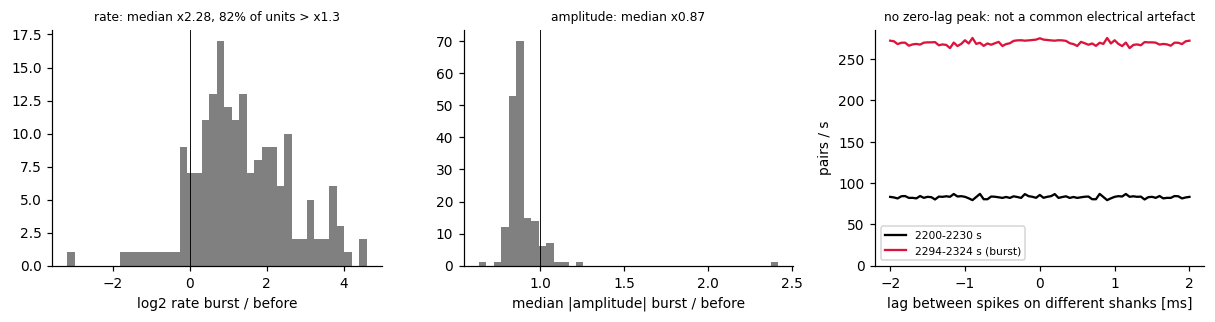

In [21]:
# what changes in the burst (outside the malfunction window) vs the 9 min before it
base = (t_sg >= 1700) & (t_sg < BURST[0] - 10)
burst_ok = in_burst_t & ~sg.in_malfunction_window.values
dur_base = BURST[0] - 10 - 1700
dur_burst = (BURST[1] - BURST[0]) - (MAL[1] - MAL[0])
cid = sg.cluster_id.values
r_base = pd.Series(cid[base]).value_counts() / dur_base; r_burst = pd.Series(cid[burst_ok]).value_counts() / dur_burst
ratio = (r_burst / r_base).dropna()
a_ratio = (pd.Series(amp[burst_ok]).groupby(cid[burst_ok]).median() / pd.Series(amp[base]).groupby(cid[base]).median()).dropna()

def cross_shank_lags(mask, maxlag=40):
    """Histogram of lags [samples] between spikes on different shanks, per second of data."""
    s_, sh_ = sid_sg[mask], sg.shank.values[mask]
    lo, hi = np.searchsorted(s_, s_ - maxlag), np.searchsorted(s_, s_ + maxlag, side='right')
    h = np.zeros(2 * maxlag + 1)
    for i in range(len(s_)):
        j = np.arange(lo[i], hi[i]); j = j[sh_[j] != sh_[i]]
        np.add.at(h, s_[j] - s_[i] + maxlag, 1)
    return h
order_t = np.argsort(sid_sg, kind='stable'); assert (order_t == np.arange(len(order_t))).all()   # spikes are time-sorted
h_base = cross_shank_lags((t_sg >= 2200) & (t_sg < 2230)) / 30
h_burst = cross_shank_lags((t_sg >= 2294) & (t_sg < 2324)) / 30

fig, axes = plt.subplots(1, 3, figsize=(11, 3))
axes[0].hist(np.log2(ratio), bins=40, color='grey'); axes[0].axvline(0, color='k', lw=.6)
axes[0].set_xlabel('log2 rate burst / before'); axes[0].set_title(f'rate: median x{ratio.median():.2f}, {(ratio > 1.3).mean():.0%} of units > x1.3', fontsize=8)
axes[1].hist(a_ratio, bins=40, color='grey'); axes[1].axvline(1, color='k', lw=.6)
axes[1].set_xlabel('median |amplitude| burst / before'); axes[1].set_title(f'amplitude: median x{a_ratio.median():.2f}', fontsize=8)
lag_ms = np.arange(-40, 41) / 20
axes[2].plot(lag_ms, h_base, color='k', label='2200-2230 s'); axes[2].plot(lag_ms, h_burst, color='crimson', label='2294-2324 s (burst)')
axes[2].set_xlabel('lag between spikes on different shanks [ms]'); axes[2].set_ylabel('pairs / s'); axes[2].legend(fontsize=7)
axes[2].set_title('no zero-lag peak: not a common electrical artefact', fontsize=8); axes[2].set_ylim(0)
plt.tight_layout()
print(f'spikes >= unit median amplitude: {large[base].sum() / dur_base:.0f} Hz before vs {large[burst_ok].sum() / dur_burst:.0f} Hz in the burst; '
      f'all spikes {base.sum() / dur_base:.0f} Hz vs {burst_ok.sum() / dur_burst:.0f} Hz')

**Burst verdict.** In the ~80 s around the malfunction window almost every unit roughly doubles its rate, on all shanks. The extra
spikes are all small: the rate of spikes at or above each unit's usual median amplitude does not change, and every unit's median
amplitude drops by ~14 %. There is no zero-lag coincidence across shanks and the raw noise level is unchanged, so it is not a
common-mode electrical artefact; head movement is not unusual either. Most likely, low-amplitude events (more distant cells, multi-unit
activity, or a change in the signal around the logger malfunction) were assigned to the units. It also starts and stops abruptly (within a second), which looks more like a change in the recording than in behaviour.
**Treat the burst window as unreliable for
unit-level analyses**, or check it against the video before using it.

In [22]:
# reliability flags on the spike table, and how many single-unit spikes each removes
spikes['in_burst_window'] = (spikes.sample_id.values >= BURST[0] * 20_000) & (spikes.sample_id.values < BURST[1] * 20_000) \
                            & ~spikes.in_malfunction_window.values
pad30 = pads.assign(start_sample=pads.start_sample - 600, end_sample=pads.end_sample + 600)
spikes['within_30ms_of_pad'] = in_intervals(spikes.sample_id.values, pad30) & ~spikes.in_zero_pad.values
spikes['reliable'] = ~(spikes.in_zero_pad | spikes.within_30ms_of_pad | spikes.in_malfunction_window | spikes.in_burst_window)
s1 = spikes[spikes.cluster_id.isin(single.cluster_id)]
pd.DataFrame({'spikes (single units)': [s1[c].sum() for c in ['in_zero_pad', 'within_5ms_of_pad', 'within_30ms_of_pad', 'in_malfunction_window', 'in_burst_window']]
                                       + [(~s1.reliable).sum(), s1.reliable.sum()],
              'seconds': [len(pads) * .192, len(pads) * .010, len(pads) * .060, MAL[1] - MAL[0], BURST[1] - BURST[0] - (MAL[1] - MAL[0]), np.nan, np.nan]},
             index=['in_zero_pad', 'within_5ms_of_pad', 'within_30ms_of_pad (incl. 5 ms)', 'in_malfunction_window', 'in_burst_window (outside malfunction)',
                    'excluded total', 'reliable']).round(1)

,spikes (single units),seconds
in_zero_pad,765,10.2
within_5ms_of_pad,2566,0.5
within_30ms_of_pad (incl. 5 ms),4702,3.2
in_malfunction_window,35696,24.1
in_burst_window (outside malfunction),145378,56.9
excluded total,181482,NaN
reliable,4184336,NaN


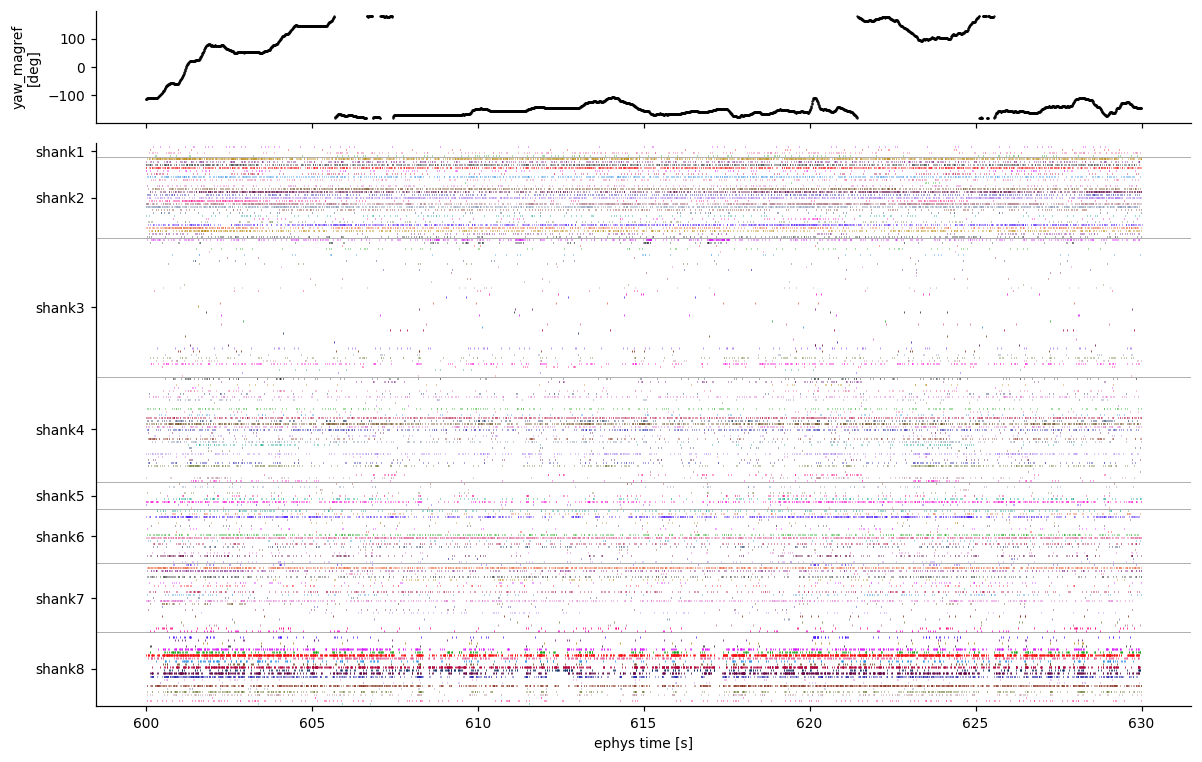

In [23]:
# raster for 30 s, single units sorted by shank and depth, with head yaw on top
t0, t1 = 600, 630
order = single.sort_values(['shank_id', 'depth']).cluster_id.values
row_of = {c: i for i, c in enumerate(order)}
s = spikes[(spikes.ephys_timestamp >= t0 * 1e6) & (spikes.ephys_timestamp < t1 * 1e6) & spikes.cluster_id.isin(row_of)]
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True, gridspec_kw={'height_ratios': [1, 5]})
w = (t_ori >= t0) & (t_ori < t1)
axes[0].plot(t_ori[w], yaw_magref[w], '.', ms=1, color='k'); axes[0].set_ylabel('yaw_magref\n[deg]')
axes[1].scatter(s.ephys_timestamp / 1e6, s.cluster_id.map(row_of), s=.6, c=s.cluster_color, marker='|', lw=.5)
sh = single.sort_values(['shank_id', 'depth']).shank_name.values
for i in np.flatnonzero(sh[1:] != sh[:-1]):
    axes[1].axhline(i + .5, color='grey', lw=.4)
axes[1].set_yticks([np.mean(np.flatnonzero(sh == n)) for n in pd.unique(sh)]); axes[1].set_yticklabels(pd.unique(sh))
axes[1].set_xlabel('ephys time [s]'); axes[1].set_ylim(len(order), -1); plt.tight_layout()

Text(0.5, 0, 'ephys time [s]')

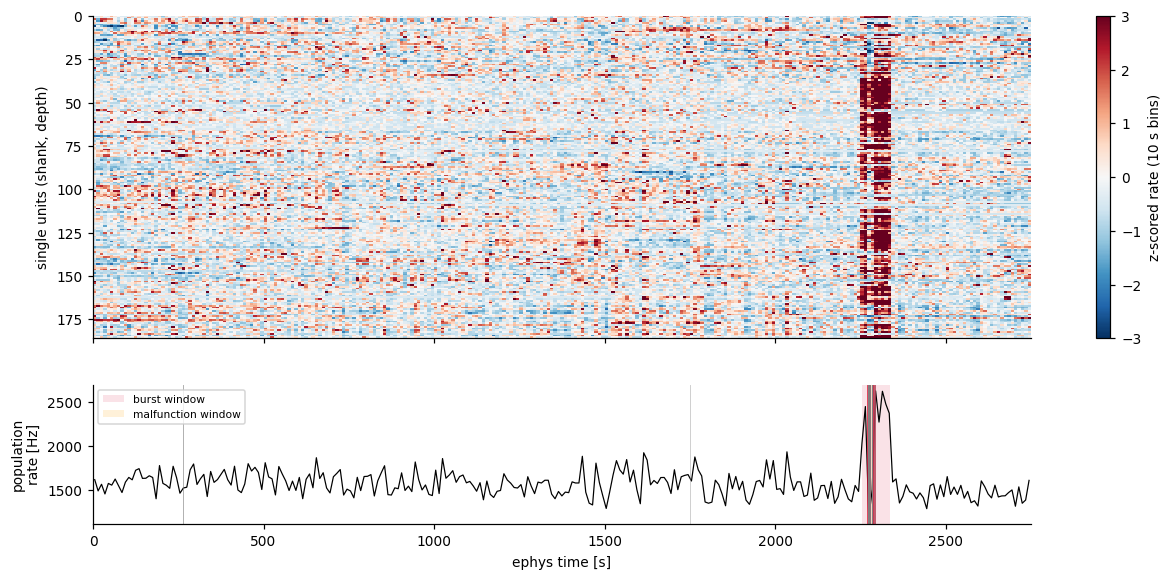

In [24]:
# firing rate stability over the session: single units, 10 s bins, z-scored per unit
edges = np.arange(0, N_SAMPLES * 50, 10e6)    # last partial bin dropped
H = np.zeros((len(order), len(edges) - 1))
hb = np.searchsorted(edges, sg.ephys_timestamp.values, side='right') - 1; hk = hb < len(edges) - 1
np.add.at(H, (sg.cluster_id.map(row_of).values[hk], hb[hk]), 1)
Z = (H - H.mean(1, keepdims=True)) / (H.std(1, keepdims=True) + 1e-9)
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True, gridspec_kw={'height_ratios': [3, 1.3]})
ax = axes[0]
im = ax.imshow(Z, aspect='auto', cmap='RdBu_r', vmin=-3, vmax=3, extent=(0, edges[-1] / 1e6, len(order), 0), interpolation='none')
plt.colorbar(im, cax=ax.inset_axes([1.07, 0, .015, 1]), label='z-scored rate (10 s bins)')
ax.set_ylabel('single units (shank, depth)')
ax = axes[1]; tc = (edges[:-1] + 5e6) / 1e6
ax.plot(tc, H.sum(0) / 10, color='k', lw=.8); ax.set_ylabel('population\nrate [Hz]')
ax.axvspan(*BURST, color='crimson', alpha=.12, lw=0, label='burst window')
shade_problems(ax, label=True); ax.legend(loc='upper left', fontsize=7); ax.set_xlabel('ephys time [s]')

## 5. Joined 40 ms table: spikes + head angle + cameras
Bins follow `FiringRate40msHz`: edges every 40 ms from 0, right-closed `(from, to]` on `ephys_timestamp` [µs].
Per bin: spike counts per single unit, head angles (6-axis; yaw also north-referenced), absolute yaw velocity, the first camera frame
(`cam_image_id`, same for all 6 cameras) and the number of frames, and reliability flags. `clean` excludes all of section 4a (`in_zero_pad` here = pad ± 30 ms).

In [25]:
BIN = 40_000
edges = np.arange(0, spikes.ephys_timestamp.max() + BIN, BIN, dtype=np.uint64)
n_bins = len(edges) - 1
def bin_of(ts_us):          # (from, to] bins; -1 / n_bins = outside
    return np.ceil(np.asarray(ts_us, dtype=np.float64) / BIN).astype(np.int64) - 1

# spikes
b = bin_of(sg.ephys_timestamp.values); k = (b >= 0) & (b < n_bins)
counts = np.zeros((n_bins, len(order)), np.uint16)
np.add.at(counts, (b[k], sg.cluster_id.map(row_of).values[k]), 1)
unit_cols = single.set_index('cluster_id').loc[order, 'cluster_id_str'].values

# orientation
ob = bin_of(ori.orientation_ephys_timestamp.values); ok = (ob >= 0) & (ob < n_bins)
def bin_mean(v):
    s_ = np.bincount(ob[ok], weights=v[ok], minlength=n_bins); n_ = np.bincount(ob[ok], minlength=n_bins)
    return np.where(n_ > 0, s_ / np.maximum(n_, 1), np.nan)
def bin_circmean(deg):
    r = np.deg2rad(deg); return np.rad2deg(np.arctan2(bin_mean(np.sin(r)), bin_mean(np.cos(r))))
yaw_rate = np.gradient(np.rad2deg(np.unwrap(np.deg2rad(ori.orientation_yaw_imu.values))), t_ori)
head = pd.DataFrame({
    'head_yaw_imu': bin_circmean(ori.orientation_yaw_imu.values), 'head_yaw_magref': bin_circmean(yaw_magref),
    'head_yaw_9axis': bin_circmean(ori.orientation_yaw.values),
    'head_pitch': bin_mean(ori.orientation_pitch_imu.values), 'head_roll': bin_mean(ori.orientation_roll_imu.values),
    'head_yaw_abs_vel': bin_mean(np.abs(yaw_rate)),
    'head_patched': bin_mean(ori.orientation_ephys_patched.values.astype(float)) > 0})

# cameras: first frame in the bin
cb = bin_of(c1.cam1_image_ephys_timestamp.values); ck = (cb >= 0) & (cb < n_bins)
first_frame = pd.Series(c1.cam1_image_id.values[ck]).groupby(cb[ck]).first()
cam = pd.DataFrame({'cam_image_id': first_frame.reindex(range(n_bins)).astype('Int64').values,
                    'cam_n_frames': np.bincount(cb[ck], minlength=n_bins)})

# reliability flags: does the bin (from, to] overlap an interval [start_sample, end_sample]
def overlaps(iv):
    m = np.zeros(n_bins + 1, int)
    lo = np.clip(bin_of(iv.start_sample.values * 50), 0, n_bins); hi = np.clip(bin_of(iv.end_sample.values * 50), 0, n_bins - 1)
    np.add.at(m, lo, 1); np.add.at(m, hi + 1, -1)
    return np.cumsum(m)[:n_bins] > 0
burst_iv = pd.DataFrame({'start_sample': [int(BURST[0] * 20_000)], 'end_sample': [int(BURST[1] * 20_000) - 1]})
flags = pd.DataFrame({'in_zero_pad': overlaps(pad30),  # pad +-30 ms
                      'in_real_data_loss': overlaps(pads[pads.category == 'zero_pad_real_data_loss']),
                      'in_malfunction_window': overlaps(malfunction), 'in_burst_window': overlaps(burst_iv)})

joined = pd.concat([pd.DataFrame({'from_ephys_timestamp': edges[:-1], 'to_ephys_timestamp': edges[1:]}),
                    head, cam, flags, pd.DataFrame(counts, columns=unit_cols)], axis=1)
joined['clean'] = ~(joined.in_zero_pad | joined.in_malfunction_window | joined.in_burst_window | joined.head_patched)
print(joined.shape, ' clean bins:', int(joined.clean.sum()), f'({joined.clean.mean():.1%})')
joined.iloc[15_000:15_005, :18]

(68816, 202)  clean bins: 66770 (97.0%)


,from_ephys_timestamp,to_ephys_timestamp,head_yaw_imu,head_yaw_magref,head_yaw_9axis,head_pitch,head_roll,head_yaw_abs_vel,head_patched,cam_image_id,cam_n_frames,in_zero_pad,in_real_data_loss,in_malfunction_window,in_burst_window,Unit0004,Unit0003,Unit0001
15000,600000000,600040000,24.366196,-112.473373,161.033529,-2.057210,-54.521312,93.389692,False,17937,2,False,False,False,False,0,0,0
15001,600040000,600080000,27.572292,-109.175187,164.052560,-3.259967,-56.326700,53.598213,False,17939,1,False,False,False,False,0,0,0
15002,600080000,600120000,28.514630,-108.140761,164.848098,-4.368894,-53.801923,4.720212,False,17940,1,False,False,False,False,0,0,1
15003,600120000,600160000,28.470363,-108.092938,164.684617,-4.099170,-48.432896,12.984378,False,17941,1,False,False,False,False,0,1,0
15004,600160000,600200000,27.511872,-108.959339,163.507718,-3.219400,-45.863762,22.262541,False,17942,1,False,False,False,False,0,0,0


In [26]:
# sanity: spike counts in the joined table equal the spike table; frames in bins equal the frame table
assert counts.sum() == ((sg.ephys_timestamp > 0) & (sg.ephys_timestamp <= edges[-1])).sum()
assert joined.cam_n_frames.sum() == ck.sum()
print('bins with 0 / 1 / 2 frames:', joined.cam_n_frames.value_counts().sort_index().to_dict())

bins with 0 / 1 / 2 frames: {0: 1311, 1: 54010, 2: 13495}


In [27]:
# head-direction tuning (12 x 30 deg) of single units on clean bins, against a circular time-shift shuffle, for each yaw version
ang = np.deg2rad(np.arange(12) * 30 - 165)
def mvl(T): return np.abs((T * np.exp(1j * ang)[:, None]).sum(0)) / T.sum(0)
def hd_tuning(yaw_col, n_shuffle=200, seed=1):
    J = joined[joined.clean & joined[yaw_col].notna()]
    onehot = np.eye(12)[np.clip(((J[yaw_col].values + 180) // 30).astype(int), 0, 11)]
    occ_s = onehot.sum(0) * BIN / 1e6
    C = J[unit_cols].values.astype(float)
    tuning = lambda Cm: (onehot.T @ Cm) / occ_s[:, None]         # Hz, 12 x units
    T = tuning(C); r = mvl(T)
    rng = np.random.default_rng(seed)
    null = np.array([mvl(tuning(np.roll(C, rng.integers(750, len(C) - 750), axis=0))) for _ in range(n_shuffle)])   # shifts >= 30 s
    return T, r, np.nanpercentile(null, 99, axis=0)
HD = {c: hd_tuning(c) for c in ['head_yaw_magref', 'head_yaw_imu', 'head_yaw_9axis']}
pd.DataFrame({c: {'units > shuffle p99': int((r > p99).sum()), 'median MVL': np.nanmedian(r)} for c, (T, r, p99) in HD.items()}).T.round(3)

,units > shuffle p99,median MVL
head_yaw_magref,71.0,0.057
head_yaw_imu,35.0,0.036
head_yaw_9axis,6.0,0.030


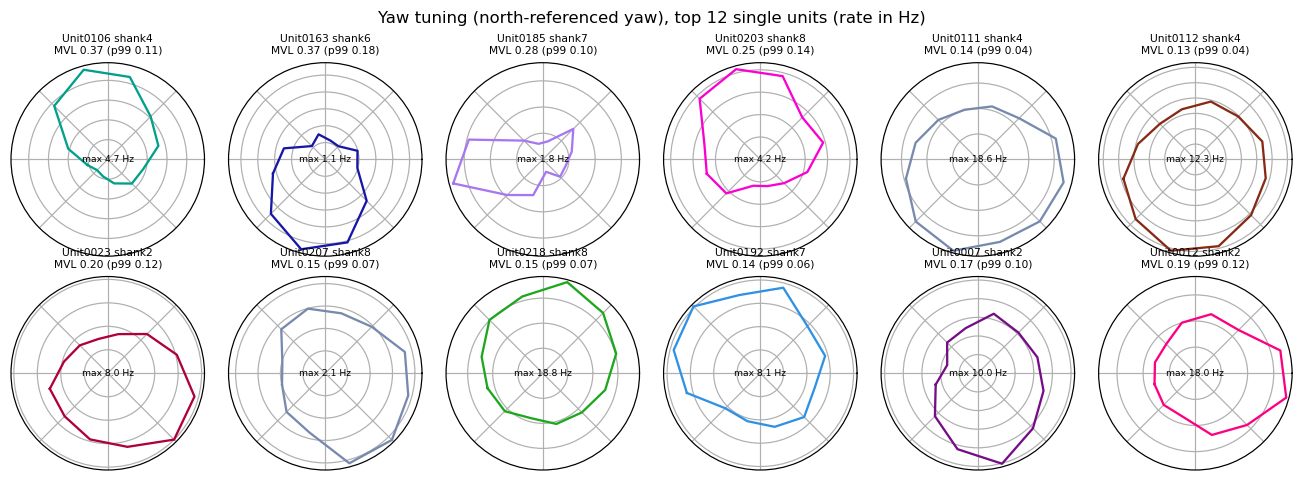

In [28]:
T, r, p99 = HD['head_yaw_magref']
top = np.argsort(-np.nan_to_num(r - p99))[:12]
fig, axes = plt.subplots(2, 6, figsize=(12, 4.4), subplot_kw={'projection': 'polar'})
for ax, u in zip(axes.ravel(), top):
    ax.plot(np.r_[ang, ang[0]], np.r_[T[:, u], T[0, u]], color=single.set_index('cluster_id').loc[order[u], 'cluster_color'])
    ax.set_title(f'{unit_cols[u]} {single.set_index("cluster_id").loc[order[u], "shank_name"]}\nMVL {r[u]:.2f} (p99 {p99[u]:.2f})', fontsize=7)
    ax.set_xticklabels([]); ax.set_yticklabels([]); ax.text(0, 0, f'max {T[:, u].max():.1f} Hz', ha='center', va='center', fontsize=6)
fig.suptitle('Yaw tuning (north-referenced yaw), top 12 single units (rate in Hz)'); plt.tight_layout()

## 6. Summary: what is reliable
| Modality | Verdict | Exclude / caveat |
|---|---|---|
| IMU (acc, gyro) | good: 6.67 kHz, every gap is a zero pad, no NaN, gyro never saturates | 19 accelerometer samples at ±16 g |
| magnetometer | good signal (\|B\| ≈ 38 µT) | its **y axis is flipped** relative to the IMU frame |
| barometer, luxmeter, power | good: every gap is a zero pad, no NaN | – |
| orientation, 6-axis (`*_imu`) | **use this**: integrated gyro (r ≥ 0.997 per axis), pitch/roll within ~1° of gravity | leads the gyro by ~4 ms; yaw is relative and drifts (~25°/min, jump at the malfunction window); `ephys_patched` samples are interpolated |
| orientation, 9-axis (`orientation_yaw/pitch/roll`, `q_*`) | **do not use**: fused with the mis-oriented magnetometer | – |
| `yaw_magref` (this notebook only) | north-referenced 6-axis yaw; HD tuning: 71 units vs 35 (6-axis) and 6 (9-axis) above shuffle | 10 s reference; check against video-based head direction before relying on it |
| cameras (6×) | good: no dropped frames, ±30 µs frame jitter in true time | 61 frames with interpolated time; none before 1.7 s |
| spikes | good outside the intervals on the right (see the table in 4a for counts) | zero pads ± 30 ms, malfunction window 2268.7-2292.8 s, burst window around it (~2256-2337 s) |
| ephys traces | 6 real 192 ms data losses, all inside the malfunction window; 47 spurious zero pads shift ephys time vs real time | use `timebase_segments` for real time |

For unit-level analyses on this session: keep spikes with `reliable`, and 40 ms bins with `clean` (97 % of the session).